# 확률분포와 손실 함수: MSE = 정규분포 MLE, Cross-Entropy = 베르누이/카테고리 MLE

**목표**

- 정규분포 2종의 PDF와 베르누이 2종의 PMF를 그려 비교하고, Softmax 출력 합이 1임을 확인한다.
- **MSE**가 정규분포 가정의 최대가능도추정(MLE)이고 **Cross-Entropy**가 베르누이/카테고리 가정의 MLE임을 수식으로 유도하고 수치로 확인한다.
- 보너스: 엔트로피, Cross-Entropy, KL-Divergence를 직접 구현해 $H(p,q)=H(p)+D_{KL}(p\|q)$를 확인한다.

**읽는 순서**: 1 분포 → 2 Softmax → 3 MSE와 정규분포 MLE → 4 Cross-Entropy와 베르누이/카테고리 MLE → 5 엔트로피·KL (보너스) → 정리

구현은 [`src/probability.py`](../src/probability.py)에 있다. 이 노트북은 그 함수를 호출하고 유도 과정을 설명한다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from src import probability as pr
from src.plotting import AQUA, BLUE, INK_SECONDARY, ORANGE, YELLOW, save_figure, setup_style

np.random.seed(42)
setup_style()
np.set_printoptions(precision=4, suppress=True)

## 1. 확률분포

### 1-1. 정규분포 PDF 2종

$$
f(x;\mu,\sigma)=\frac{1}{\sigma\sqrt{2\pi}}\exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)
$$

비교할 두 분포는 $N(0,\,1^2)$과 $N(2,\,0.5^2)$이다. 평균 $\mu$는 봉우리의 위치, 표준편차 $\sigma$는 퍼진 정도를 정한다.

### 1-2. 베르누이 PMF 2종

$$
P(K=k)=p^{k}(1-p)^{1-k},\qquad k\in\{0,1\}
$$

비교할 두 분포는 $p=0.5$(공정한 동전)와 $p=0.8$(편향된 동전)이다.

분포            봉우리 높이 f(μ)       PDF 면적      P(μ-σ<X<μ+σ)      표본평균 / 표본표준편차(5000개)
N(0.0, 1.0²)  0.3989            1.0000      0.6803            0.006 / 0.996
N(2.0, 0.5²)  0.7979            1.0000      0.6778            1.995 / 0.505

Bernoulli(0.5): P(0)=0.50, P(1)=0.50, 합=1.00  | 10000번 시뮬레이션 1의 비율 = 0.5124
Bernoulli(0.8): P(0)=0.20, P(1)=0.80, 합=1.00  | 10000번 시뮬레이션 1의 비율 = 0.8055


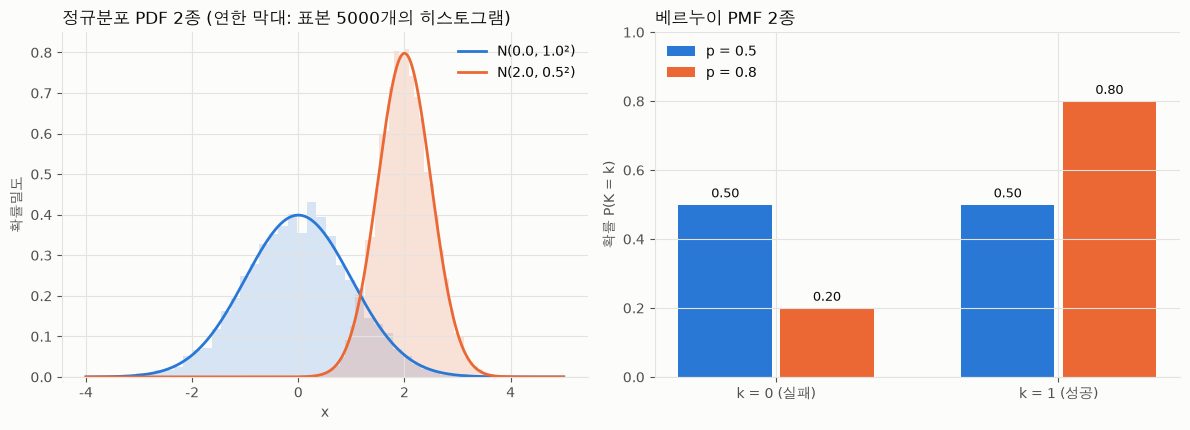

In [2]:
x = np.linspace(-4, 5, 901)
dx = x[1] - x[0]
normals = [(0.0, 1.0, BLUE), (2.0, 0.5, ORANGE)]

samples = {(mu, s): np.random.normal(mu, s, 5000) for mu, s, _ in normals}   # 시드 42 고정 후 표본 추출

print(f"{'분포':<14}{'봉우리 높이 f(μ)':<18}{'PDF 면적':<12}{'P(μ-σ<X<μ+σ)':<18}표본평균 / 표본표준편차(5000개)")
for mu, s, _ in normals:
    pdf = pr.normal_pdf(x, mu, s)
    inside = (x > mu - s) & (x < mu + s)
    sample = samples[(mu, s)]
    print(f"N({mu}, {s}²)".ljust(14) + f"{pr.normal_pdf(mu, mu, s):<18.4f}{pdf.sum() * dx:<12.4f}{pdf[inside].sum() * dx:<18.4f}{sample.mean():.3f} / {sample.std():.3f}")

pmf_rows = [(0.5, BLUE), (0.8, ORANGE)]
print()
for p, _ in pmf_rows:
    pmf = pr.bernoulli_pmf(np.array([0, 1]), p)
    draws = np.random.binomial(1, p, 10000)
    print(f"Bernoulli({p}): P(0)={pmf[0]:.2f}, P(1)={pmf[1]:.2f}, 합={pmf.sum():.2f}  | 10000번 시뮬레이션 1의 비율 = {draws.mean():.4f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.4))
for mu, s, color in normals:
    sns.histplot(samples[(mu, s)], stat="density", bins=40, color=color, alpha=0.18, edgecolor="none", ax=left)
    left.plot(x, pr.normal_pdf(x, mu, s), color=color, label=f"N({mu}, {s}²)")
left.set_xlabel("x")
left.set_ylabel("확률밀도")
left.set_title("정규분포 PDF 2종 (연한 막대: 표본 5000개의 히스토그램)", loc="left")
left.legend()

width = 0.36
for i, (p, color) in enumerate(pmf_rows):
    pmf = pr.bernoulli_pmf(np.array([0, 1]), p)
    bars = right.bar(np.array([0, 1]) + (i - 0.5) * width, pmf, width=width * 0.92, color=color, label=f"p = {p}")
    right.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
right.set_xticks([0, 1])
right.set_xticklabels(["k = 0 (실패)", "k = 1 (성공)"])
right.set_ylabel("확률 P(K = k)")
right.set_ylim(0, 1.0)
right.set_title("베르누이 PMF 2종", loc="left")
right.legend()
fig.tight_layout()
save_figure(fig, "distributions.png")
plt.show()

**해석**

- 두 PDF의 면적은 모두 1이고, $\mu\pm\sigma$ 안의 확률은 약 0.683이다. $\sigma$가 달라도 이 비율은 같다.
- $N(2,0.5^2)$의 봉우리가 $N(0,1)$의 약 2배($0.798$ vs $0.399$)인 이유는 면적 1을 절반 폭에 담아야 하기 때문이다. **PDF의 값은 확률이 아니라 밀도**라서 $\sigma$가 아주 작으면 1을 넘을 수도 있다(구간에서 적분해야 확률이 된다).
- 베르누이는 $p$가 바뀌어도 두 막대의 합이 1이다. $p=0.8$로 시뮬레이션하면 1의 비율이 0.8 근처로 모이는데, 이것이 4장에서 볼 MLE $\hat p=\bar y$의 출발점이다.

## 2. Softmax

$$
\mathrm{softmax}(z)_i=\frac{e^{z_i}}{\sum_{j}e^{z_j}}
$$

- 모든 출력이 양수이고 **합이 1**이라 확률분포로 읽을 수 있다.
- 순서를 보존한다($z_i$가 크면 $p_i$도 크다).
- **평행이동에 불변**이다: 모든 $z_i$에서 같은 $c$를 빼도 분자와 분모에 $e^{-c}$가 똑같이 곱해져 결과가 같다. 그래서 $c=\max z$를 빼서 $\exp$의 입력을 모두 0 이하로 만들면 **오버플로를 피할 수 있다**.

In [3]:
logits = np.random.randn(1000, 10) * 5.0        # 1000개 샘플, 10개 클래스
probs = pr.softmax(logits)
deviation = np.max(np.abs(probs.sum(axis=1) - 1.0))
print(f"1000×10 무작위 logits: 각 행 합과 1.0의 최대 오차 = {deviation:.2e}   (허용 1e-6)")
assert deviation < 1e-6 and (probs > 0).all()

big = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(all="ignore"):
    naive = np.exp(big) / np.exp(big).sum()      # exp(1000) = inf → inf/inf = nan
print("\nz = [1000, 1001, 1002]")
print("  안정화 없이:", naive, "  ← exp가 넘쳐 nan")
print("  최댓값 빼기:", np.round(pr.softmax(big), 4), f"  합 = {pr.softmax(big).sum():.6f}")
print("  [0, 1, 2]와 같은 출력인가?", np.allclose(pr.softmax(big), pr.softmax(np.array([0.0, 1.0, 2.0]))))

1000×10 무작위 logits: 각 행 합과 1.0의 최대 오차 = 4.44e-16   (허용 1e-6)

z = [1000, 1001, 1002]
  안정화 없이: [nan nan nan]   ← exp가 넘쳐 nan
  최댓값 빼기: [0.09   0.2447 0.6652]   합 = 1.000000
  [0, 1, 2]와 같은 출력인가? True


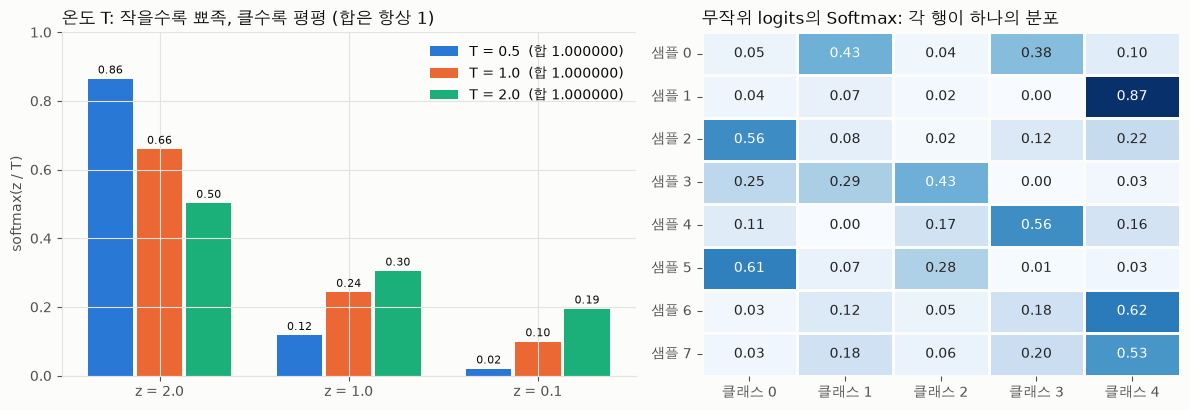

heatmap 각 행의 합: [1. 1. 1. 1. 1. 1. 1. 1.]


In [4]:
z = np.array([2.0, 1.0, 0.1])
temperatures = [0.5, 1.0, 2.0]
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})

width = 0.26
for i, (T, color) in enumerate(zip(temperatures, (BLUE, ORANGE, AQUA))):
    p = pr.softmax(z / T)
    bars = left.bar(np.arange(3) + (i - 1) * width, p, width=width * 0.92, color=color, label=f"T = {T}  (합 {p.sum():.6f})")
    left.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
left.set_xticks(range(3))
left.set_xticklabels([f"z = {v}" for v in z])
left.set_ylabel("softmax(z / T)")
left.set_ylim(0, 1.0)
left.set_title("온도 T: 작을수록 뾰족, 클수록 평평 (합은 항상 1)", loc="left")
left.legend()

demo = np.vstack([pr.softmax(row) for row in np.random.randn(8, 5) * 2.0])
sns.heatmap(demo, annot=True, fmt=".2f", cmap="Blues", cbar=False, linewidths=1, linecolor="#fcfcfb",
            xticklabels=[f"클래스 {c}" for c in range(5)], yticklabels=[f"샘플 {r}" for r in range(8)], ax=right)
right.set_title("무작위 logits의 Softmax: 각 행이 하나의 분포", loc="left")
right.grid(False)
fig.tight_layout()
save_figure(fig, "softmax_demo.png")
plt.show()
print("heatmap 각 행의 합:", np.round(demo.sum(axis=1), 6))

## 3. MSE = 정규분포 가정의 MLE

### 가정과 가능도

예측값 $f_i=f(x_i;\theta)$에 **평균 0인 가우시안 노이즈**가 독립적으로 더해져 관측값이 만들어졌다고 가정한다.

$$
y_i=f_i+\varepsilon_i,\quad \varepsilon_i\sim N(0,\sigma^2)\ \text{i.i.d.}\ \Longrightarrow\ y_i\mid x_i\sim N(f_i,\sigma^2)
$$

데이터가 독립이므로 가능도는 곱이다.

$$
\mathcal L(\theta)=\prod_{i=1}^{n}\frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\frac{(y_i-f_i)^2}{2\sigma^2}\right)
$$

### 로그를 취해 합으로

$\ln$은 단조증가라 $\mathcal L$을 최대화하는 $\theta$와 $\ln\mathcal L$을 최대화하는 $\theta$가 같다.

$$
\ln\mathcal L(\theta)=-\frac n2\ln(2\pi\sigma^2)-\frac{1}{2\sigma^2}\sum_{i=1}^n(y_i-f_i)^2
$$

$\theta$에 의존하는 것은 둘째 항뿐이고 그 계수 $\tfrac1{2\sigma^2}$는 양수이므로

$$
\hat\theta_{\text{MLE}}=\arg\max_\theta\ln\mathcal L=\arg\min_\theta\sum_{i=1}^n(y_i-f_i)^2=\arg\min_\theta\underbrace{\frac1n\sum_{i=1}^n(y_i-f_i)^2}_{\text{MSE}}
$$

**$\sigma$ 값을 몰라도 $\theta$의 최적해는 같다.** 노이즈 크기는 최적 위치가 아니라 손실의 눈금만 바꾼다.

### 가장 단순한 모형으로 확인: $f_i=\mu$

$$
\frac{\partial\ln\mathcal L}{\partial\mu}=\frac1{\sigma^2}\sum_i(y_i-\mu)=0\ \Longrightarrow\ \hat\mu=\bar y\quad(\text{표본평균})
$$

$$
\frac{\partial\ln\mathcal L}{\partial\sigma^2}=-\frac n{2\sigma^2}+\frac{\sum_i(y_i-\hat\mu)^2}{2\sigma^4}=0\ \Longrightarrow\ \hat\sigma^2=\frac1n\sum_i(y_i-\bar y)^2=\mathrm{MSE}(\hat\mu)
$$

분산의 MLE는 $n-1$이 아니라 $n$으로 나눈다(편향 추정량).

### 의미

MSE를 쓴다는 것은 **오차가 평균 0인 가우시안**이라고 믿는 것이다. 가우시안은 꼬리가 얇아서 큰 오차의 로그 가능도 페널티가 제곱으로 커지므로, 이상치가 있는 데이터에서 MSE가 민감한 이유가 여기서 나온다. 라플라스 노이즈를 가정하면 같은 유도가 MAE로 이어진다.

표본평균 ȳ = 3.0766   MLE μ̂ = 3.0766
NLL이 최소인 μ  = 3.0770
MSE가 최소인 μ  = 3.0770   (격자 간격 0.001)

NLL(μ=2.5)             = 442.531883
n/2·ln(2πσ²)+n·MSE/2σ² = 442.531883   (같아야 함)

σ의 MLE (닫힌 해) = 2.1147   격자에서 NLL이 최소인 σ = 2.1150
σ̂² = MSE(μ̂) = 4.4721   (표본분산 n-1 : 4.4946)


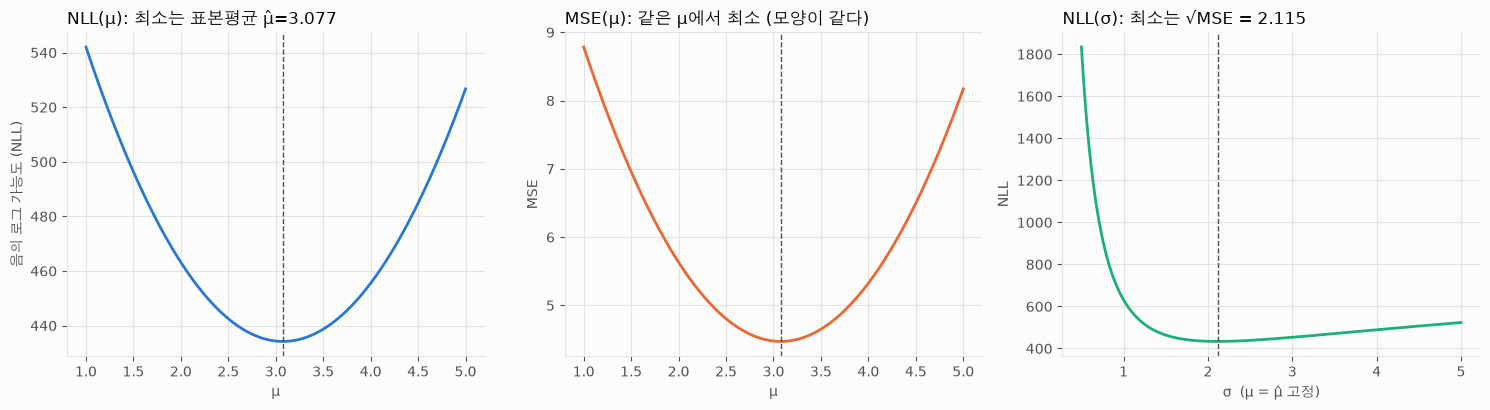

In [5]:
true_mu, true_sigma, n = 3.0, 2.0, 200
y = np.random.normal(true_mu, true_sigma, n)

mus = np.linspace(1.0, 5.0, 4001)
nll = np.array([pr.normal_nll(y, m, true_sigma) for m in mus])
mse_curve = np.array([pr.mse(y, m) for m in mus])

mu_hat, sigma_hat = pr.normal_mle(y)
print(f"표본평균 ȳ = {y.mean():.4f}   MLE μ̂ = {mu_hat:.4f}")
print(f"NLL이 최소인 μ  = {mus[nll.argmin()]:.4f}")
print(f"MSE가 최소인 μ  = {mus[mse_curve.argmin()]:.4f}   (격자 간격 0.001)")
assert mus[nll.argmin()] == mus[mse_curve.argmin()]

# 항등식: NLL = n/2 · ln(2πσ²) + n · MSE / (2σ²)
mu_test = 2.5
identity = 0.5 * n * np.log(2 * np.pi * true_sigma**2) + n * pr.mse(y, mu_test) / (2 * true_sigma**2)
print(f"\nNLL(μ=2.5)             = {pr.normal_nll(y, mu_test, true_sigma):.6f}")
print(f"n/2·ln(2πσ²)+n·MSE/2σ² = {identity:.6f}   (같아야 함)")
assert np.isclose(pr.normal_nll(y, mu_test, true_sigma), identity)

sigmas = np.linspace(0.5, 5.0, 4501)
nll_sigma = np.array([pr.normal_nll(y, mu_hat, s) for s in sigmas])
print(f"\nσ의 MLE (닫힌 해) = {sigma_hat:.4f}   격자에서 NLL이 최소인 σ = {sigmas[nll_sigma.argmin()]:.4f}")
print(f"σ̂² = MSE(μ̂) = {pr.mse(y, mu_hat):.4f}   (표본분산 n-1 : {y.var(ddof=1):.4f})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(mus, nll, color=BLUE)
axes[0].axvline(mu_hat, color=INK_SECONDARY, linestyle="--", linewidth=1.0)
axes[0].set_xlabel("μ")
axes[0].set_ylabel("음의 로그 가능도 (NLL)")
axes[0].set_title(f"NLL(μ): 최소는 표본평균 μ̂={mu_hat:.3f}", loc="left")
axes[1].plot(mus, mse_curve, color=ORANGE)
axes[1].axvline(mu_hat, color=INK_SECONDARY, linestyle="--", linewidth=1.0)
axes[1].set_xlabel("μ")
axes[1].set_ylabel("MSE")
axes[1].set_title("MSE(μ): 같은 μ에서 최소 (모양이 같다)", loc="left")
axes[2].plot(sigmas, nll_sigma, color=AQUA)
axes[2].axvline(sigma_hat, color=INK_SECONDARY, linestyle="--", linewidth=1.0)
axes[2].set_xlabel("σ  (μ = μ̂ 고정)")
axes[2].set_ylabel("NLL")
axes[2].set_title(f"NLL(σ): 최소는 √MSE = {sigma_hat:.3f}", loc="left")
fig.tight_layout()
save_figure(fig, "mse_mle.png")
plt.show()

## 4. Cross-Entropy = 베르누이/카테고리 가정의 MLE

### 4-1. 베르누이와 Binary Cross-Entropy

레이블 $y_i\in\{0,1\}$이 확률 $p$로 성공하는 베르누이에서 나왔다고 가정한다. $P(y_i\mid p)=p^{y_i}(1-p)^{1-y_i}$이므로

$$
\ln\mathcal L(p)=\sum_{i=1}^n\big[y_i\ln p+(1-y_i)\ln(1-p)\big]=n\big[\bar y\ln p+(1-\bar y)\ln(1-p)\big]=-n\cdot\mathrm{BCE}
$$

$$
\frac{\partial\ln\mathcal L}{\partial p}=n\left[\frac{\bar y}{p}-\frac{1-\bar y}{1-p}\right]=0\ \Longrightarrow\ \hat p=\bar y
$$

2차 미분 $-n\big[\bar y/p^2+(1-\bar y)/(1-p)^2\big]<0$이므로 최댓값이다. **MLE는 1의 비율**이다. 모델이 샘플마다 $p_i=\sigma(z_i)$를 낸다면 $-\ln\mathcal L/n$이 그대로 BCE이므로 **BCE 최소화 = 베르누이 MLE**다.

### 4-2. 카테고리와 Categorical Cross-Entropy

클래스 $K$개, 원-핫 레이블 $y_{ic}$, 클래스 확률 $p_c$ ($\sum_cp_c=1$)이면 $P(y_i\mid p)=\prod_cp_c^{y_{ic}}$이고 $n_c=\sum_iy_{ic}$라 두면

$$
\ln\mathcal L(p)=\sum_{i}\sum_c y_{ic}\ln p_c=\sum_c n_c\ln p_c
$$

합이 1이라는 제약 아래 최대화하려고 라그랑주 승수 $\lambda$를 쓴다.

$$
\frac{\partial}{\partial p_c}\Big[\sum_c n_c\ln p_c-\lambda\big(\textstyle\sum_cp_c-1\big)\Big]=\frac{n_c}{p_c}-\lambda=0\ \Longrightarrow\ p_c=\frac{n_c}{\lambda}
$$

$\sum_cp_c=1$에서 $\lambda=n$이므로 $\hat p_c=n_c/n$, 즉 **클래스 빈도**다. 모델이 $p_{ic}=\mathrm{softmax}(z_i)_c$를 낸다면 $-\ln\mathcal L/n=-\frac1n\sum_i\sum_cy_{ic}\ln p_{ic}$는 정확히 Categorical Cross-Entropy다. 따라서 **CE 최소화 = 카테고리 MLE**다.

### 4-3. Softmax + Cross-Entropy의 기울기

$\partial p_c/\partial z_j=p_c(\delta_{cj}-p_j)$이고 $L=-\sum_cy_c\ln p_c$이므로

$$
\frac{\partial L}{\partial z_j}=-\sum_c\frac{y_c}{p_c}\,p_c(\delta_{cj}-p_j)=-y_j+p_j\sum_cy_c=p_j-y_j
$$

원-핫이라 $\sum_cy_c=1$이다. 이진 경우의 $\hat y-y$와 같은 꼴이고, 역전파 노트북의 $\partial L/\partial z_2=\hat y-y$가 바로 이것이다.

1의 개수 77 / 100  →  MLE p̂ = 0.7700
BCE가 최소인 p = 0.7700   NLL이 최소인 p = 0.7700
NLL = n × BCE ?  True

클래스 개수 [154, 85, 61]  →  MLE p̂ = [0.5133, 0.2833, 0.2033]  (= 빈도)


p̂의 CE = 1.023518   무작위 분포 20000개 중 최소 CE = 1.023519   (차이 1.5e-06 ≥ 0)
→ 어떤 후보도 클래스 빈도 p̂보다 CE가 작지 않다.


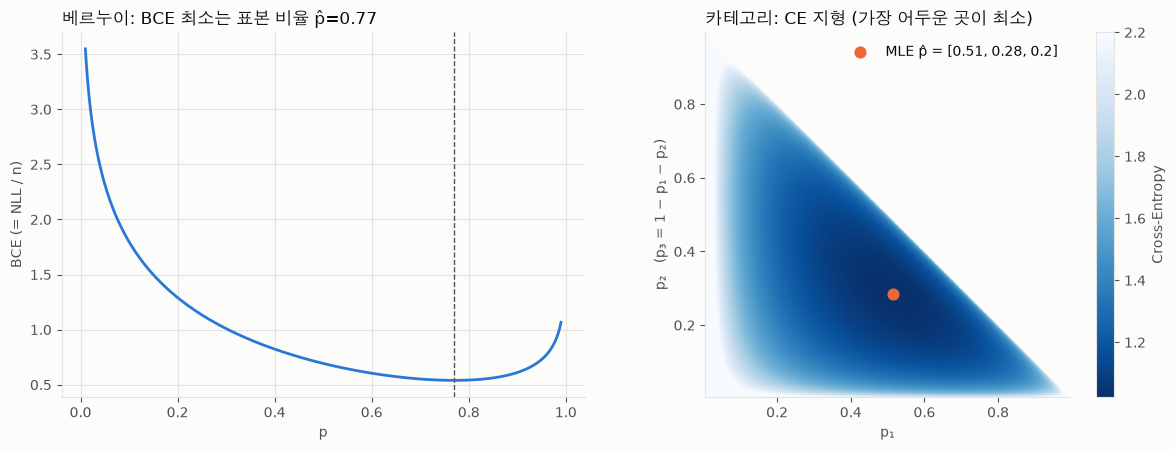

In [6]:
true_p, n_b = 0.7, 100
yb = np.random.binomial(1, true_p, n_b).astype(float)

ps = np.linspace(0.01, 0.99, 981)
bce_curve = np.array([pr.binary_cross_entropy(yb, np.full(n_b, p)) for p in ps])
nll_curve = np.array([pr.bernoulli_nll(yb, np.full(n_b, p)) for p in ps])

p_hat = pr.bernoulli_mle(yb)
print(f"1의 개수 {int(yb.sum())} / {n_b}  →  MLE p̂ = {p_hat:.4f}")
print(f"BCE가 최소인 p = {ps[bce_curve.argmin()]:.4f}   NLL이 최소인 p = {ps[nll_curve.argmin()]:.4f}")
print(f"NLL = n × BCE ?  {np.allclose(nll_curve, n_b * bce_curve)}")
assert abs(ps[bce_curve.argmin()] - p_hat) < 1e-3

# 카테고리: 3개 클래스
true_pc = np.array([0.5, 0.3, 0.2])
labels = np.random.choice(3, size=300, p=true_pc)
onehot = np.eye(3)[labels]
counts = onehot.sum(axis=0)
pc_hat = counts / counts.sum()
print(f"\n클래스 개수 {counts.astype(int).tolist()}  →  MLE p̂ = {np.round(pc_hat, 4).tolist()}  (= 빈도)")

def mean_nll(p):
    # 모든 샘플에 같은 분포 p를 쓸 때의 평균 음의 로그 가능도 = Cross-Entropy
    return pr.categorical_cross_entropy(onehot, np.tile(p, (len(onehot), 1)))

candidates = np.random.dirichlet(np.ones(3), size=20000)
candidate_loss = np.array([mean_nll(c) for c in candidates])
print(f"p̂의 CE = {mean_nll(pc_hat):.6f}   무작위 분포 20000개 중 최소 CE = {candidate_loss.min():.6f}   (차이 {candidate_loss.min() - mean_nll(pc_hat):.1e} ≥ 0)")
assert mean_nll(pc_hat) <= candidate_loss.min()
print("→ 어떤 후보도 클래스 빈도 p̂보다 CE가 작지 않다.")

g = np.linspace(0.005, 0.995, 200)
p1, p2 = np.meshgrid(g, g)
p3 = 1 - p1 - p2
valid = p3 > 0.003
ce_grid = -(pc_hat[0] * np.log(p1) + pc_hat[1] * np.log(p2) + pc_hat[2] * np.log(np.where(valid, p3, np.nan)))
ce_grid = np.where(valid, ce_grid, np.nan)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1]})
left.plot(ps, bce_curve, color=BLUE)
left.axvline(p_hat, color=INK_SECONDARY, linestyle="--", linewidth=1.0)
left.set_xlabel("p")
left.set_ylabel("BCE (= NLL / n)")
left.set_title(f"베르누이: BCE 최소는 표본 비율 p̂={p_hat:.2f}", loc="left")
image = right.imshow(ce_grid, origin="lower", extent=(g[0], g[-1], g[0], g[-1]), cmap="Blues_r", vmin=np.nanmin(ce_grid), vmax=2.2)
right.scatter([pc_hat[0]], [pc_hat[1]], color=ORANGE, s=60, zorder=3, label=f"MLE p̂ = {np.round(pc_hat, 2).tolist()}")
right.set_xlabel("p₁")
right.set_ylabel("p₂   (p₃ = 1 − p₁ − p₂)")
right.set_title("카테고리: CE 지형 (가장 어두운 곳이 최소)", loc="left")
right.grid(False)
right.legend(loc="upper right")
fig.colorbar(image, ax=right, label="Cross-Entropy")
fig.tight_layout()
save_figure(fig, "cross_entropy_mle.png")
plt.show()

In [7]:
# Softmax + CE 기울기 = p - y 를 수치 미분과 비교
z = np.array([0.3, -1.2, 2.0])
y_onehot = np.array([0.0, 0.0, 1.0])

def loss(logits):
    return pr.categorical_cross_entropy(y_onehot[None, :], pr.softmax(logits)[None, :])

analytic = pr.softmax_cross_entropy_grad(z, y_onehot)
h = 1e-6
numeric = np.array([(loss(z + h * e) - loss(z - h * e)) / (2 * h) for e in np.eye(3)])
print("softmax(z) =", np.round(pr.softmax(z), 4), "  y =", y_onehot)
print("p - y      =", np.round(analytic, 6))
print("수치 미분  =", np.round(numeric, 6), f"  최대 오차 {np.max(np.abs(analytic - numeric)):.1e}")
assert np.allclose(analytic, numeric, atol=1e-8)

softmax(z) = [0.1493 0.0333 0.8174]   y = [0. 0. 1.]
p - y      = [ 0.1493  0.0333 -0.1826]
수치 미분  = [ 0.1493  0.0333 -0.1826]   최대 오차 1.2e-10


### 4-4. 정리: 어떤 가정이 어떤 손실을 만드는가

| 데이터 분포 가정 | 음의 로그 가능도 | 대응하는 손실 | MLE 해 (상수 모형) |
|---|---|---|---|
| 정규분포 $N(f_i,\sigma^2)$ (회귀) | $\tfrac n2\ln(2\pi\sigma^2)+\tfrac{n}{2\sigma^2}\mathrm{MSE}$ | **MSE** | 표본평균 $\bar y$ |
| 베르누이 $\mathrm{Bern}(p_i)$ (이진 분류) | $n\cdot\mathrm{BCE}$ | **Binary Cross-Entropy** | 1의 비율 |
| 카테고리 $\mathrm{Cat}(p_{i\cdot})$ (다중 분류) | $n\cdot\mathrm{CE}$ | **Categorical Cross-Entropy** | 클래스 빈도 |

세 경우 모두 "**손실 = 가정한 분포의 음의 로그 가능도**"라는 같은 원리다. 손실 함수를 고르는 일은 곧 데이터가 어떤 분포에서 나왔다고 믿는지를 고르는 일이다. 분류에 MSE를 쓰면 이 가정과 맞지 않아 Softmax/Sigmoid 출력에서 기울기가 작아지는 구간(포화)에서 학습이 느려진다.

## 5. 보너스: 엔트로피, Cross-Entropy, KL-Divergence

$$
H(p)=-\sum_ip_i\ln p_i,\qquad
H(p,q)=-\sum_ip_i\ln q_i,\qquad
D_{KL}(p\,\|\,q)=\sum_ip_i\ln\frac{p_i}{q_i}
$$

$$
\boxed{H(p,q)=H(p)+D_{KL}(p\,\|\,q)}\qquad\text{(우변: } -\sum p\ln q=-\sum p\ln p+\sum p\ln\tfrac pq\text{)}
$$

- **엔트로피** $H(p)$: 분포 $p$ 자체의 불확실성. 균등할수록 크고($\ln n$), 한 점에 몰리면 0이다.
- **Cross-Entropy** $H(p,q)$: 진짜 분포가 $p$인데 $q$로 부호화할 때 평균 정보량.
- **KL 발산**: $q$를 쓰느라 **추가로 치르는 비용** $H(p,q)-H(p)$. Jensen 부등식으로 $-D_{KL}=\sum p\ln\frac qp\le\ln\sum p\frac qp=0$이므로 항상 $\ge0$이고, $p=q$일 때만 0이다. 대칭이 아니라서 거리가 아니다.
- 분류에서 정답 $p$는 원-핫이라 $H(p)=0$이다. 그래서 **Cross-Entropy 최소화 = KL 최소화**이고, 정답 클래스가 $c$이면 $H(p,q)=-\ln q_c$다.

In [8]:
p = np.array([0.7, 0.2, 0.1])
q = np.array([0.5, 0.3, 0.2])
print(f"p = {p}, q = {q}")
print(f"  엔트로피      H(p)      = {pr.entropy(p):.4f}   (균등분포의 최댓값 ln 3 = {np.log(3):.4f})")
print(f"  교차 엔트로피 H(p, q)   = {pr.cross_entropy(p, q):.4f}")
print(f"  KL            D(p‖q)   = {pr.kl_divergence(p, q):.4f}")
print(f"  H(p) + D(p‖q)          = {pr.entropy(p) + pr.kl_divergence(p, q):.4f}   ← H(p,q)와 같아야 함")
assert np.isclose(pr.cross_entropy(p, q), pr.entropy(p) + pr.kl_divergence(p, q))
print(f"  비대칭       D(q‖p)   = {pr.kl_divergence(q, p):.4f}   (D(p‖q)={pr.kl_divergence(p, q):.4f}와 다르다)")
print(f"  D(p‖p) = {pr.kl_divergence(p, p):.1e}   H(p, p) = {pr.cross_entropy(p, p):.4f} = H(p)")

onehot_p = np.array([0.0, 1.0, 0.0])
q_cls = np.array([0.2, 0.5, 0.3])
print(f"\n원-핫 p: H(p) = {pr.entropy(onehot_p):.1f},  H(p,q) = {pr.cross_entropy(onehot_p, q_cls):.4f}"
      f" = D(p‖q) = {pr.kl_divergence(onehot_p, q_cls):.4f} = -ln q₂ = {-np.log(0.5):.4f}")

# 정규분포 두 개의 KL: 해석해 vs 수치 적분
grid = np.linspace(-15, 15, 300001)
d = grid[1] - grid[0]
f1, f2 = pr.normal_pdf(grid, 0.0, 1.0), pr.normal_pdf(grid, 1.0, 2.0)
numeric_kl = float(np.sum(f1 * np.log(f1 / f2)) * d)
print(f"\nKL(N(0,1²) ‖ N(1,2²)): 해석해 {pr.gaussian_kl(0.0, 1.0, 1.0, 2.0):.6f}  수치 적분 {numeric_kl:.6f}")

p = [0.7 0.2 0.1], q = [0.5 0.3 0.2]
  엔트로피      H(p)      = 0.8018   (균등분포의 최댓값 ln 3 = 1.0986)
  교차 엔트로피 H(p, q)   = 0.8869
  KL            D(p‖q)   = 0.0851
  H(p) + D(p‖q)          = 0.8869   ← H(p,q)와 같아야 함
  비대칭       D(q‖p)   = 0.0920   (D(p‖q)=0.0851와 다르다)
  D(p‖p) = 0.0e+00   H(p, p) = 0.8018 = H(p)

원-핫 p: H(p) = 0.0,  H(p,q) = 0.6931 = D(p‖q) = 0.6931 = -ln q₂ = 0.6931

KL(N(0,1²) ‖ N(1,2²)): 해석해 0.443147  수치 적분 0.443147


p=(0.7, 0.2, 0.1), q=(0.5, 0.3, 0.2)     D(p‖q) = 0.085   D(q‖p) = 0.092
p=(0.5, 0.5), q=(0.99, 0.01)             D(p‖q) = 1.614   D(q‖p) = 0.637


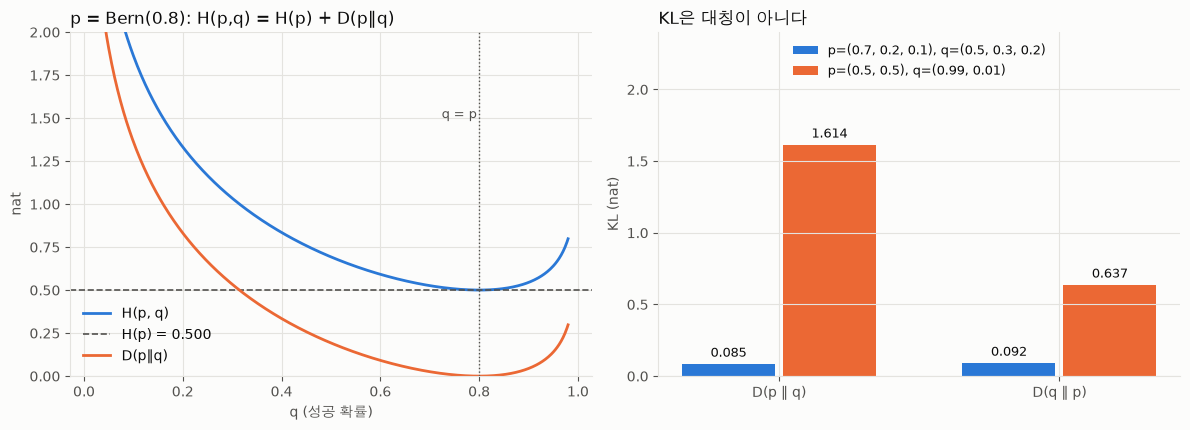

In [9]:
# 베르누이 p=0.8 을 q로 부호화할 때: H(p,q) = H(p) + KL
p_true = np.array([0.8, 0.2])
qs = np.linspace(0.02, 0.98, 481)
ce_q = np.array([pr.cross_entropy(p_true, np.array([v, 1 - v])) for v in qs])
kl_q = np.array([pr.kl_divergence(p_true, np.array([v, 1 - v])) for v in qs])
h_p = pr.entropy(p_true)
assert np.allclose(ce_q, h_p + kl_q)

pairs = {
    "p=(0.7, 0.2, 0.1), q=(0.5, 0.3, 0.2)": (np.array([0.7, 0.2, 0.1]), np.array([0.5, 0.3, 0.2])),
    "p=(0.5, 0.5), q=(0.99, 0.01)": (np.array([0.5, 0.5]), np.array([0.99, 0.01])),
}
for label, (pp, qq) in pairs.items():
    print(f"{label:<40} D(p‖q) = {pr.kl_divergence(pp, qq):.3f}   D(q‖p) = {pr.kl_divergence(qq, pp):.3f}")
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.4))
left.plot(qs, ce_q, color=BLUE, label="H(p, q)")
left.axhline(h_p, color=INK_SECONDARY, linestyle="--", linewidth=1.2, label=f"H(p) = {h_p:.3f}")
left.plot(qs, kl_q, color=ORANGE, label="D(p‖q)")
left.axvline(0.8, color=INK_SECONDARY, linestyle=":", linewidth=1.0)
left.text(0.795, 1.5, "q = p", ha="right", fontsize=9, color=INK_SECONDARY)
left.set_ylim(0, 2.0)
left.set_xlabel("q (성공 확률)")
left.set_ylabel("nat")
left.set_title("p = Bern(0.8): H(p,q) = H(p) + D(p‖q)", loc="left")
left.legend()

width = 0.36
for i, (label, (pp, qq)) in enumerate(pairs.items()):
    forward, reverse = pr.kl_divergence(pp, qq), pr.kl_divergence(qq, pp)
    bars = right.bar(np.array([0, 1]) + (i - 0.5) * width, [forward, reverse], width=width * 0.92,
                     color=(BLUE, ORANGE)[i], label=label)
    right.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
right.set_xticks([0, 1])
right.set_xticklabels(["D(p ‖ q)", "D(q ‖ p)"])
right.set_ylabel("KL (nat)")
right.set_title("KL은 대칭이 아니다", loc="left")
right.set_ylim(0, 2.4)
right.legend(loc="upper center", fontsize=9)
fig.tight_layout()
save_figure(fig, "entropy_kl.png")
plt.show()

**해석**: 왼쪽에서 $H(p,q)$는 $q=p$일 때 $H(p)$까지 내려가고 그 위의 높이가 정확히 KL이다. 학습은 모델 분포 $q$를 데이터 분포 $p$에 맞추는 일이고, Cross-Entropy를 줄이는 것과 KL을 줄이는 것은 $H(p)$가 상수라서 같은 문제다. 오른쪽에서 $q$가 $p$와 조금 다른 경우(파랑)는 $D(p\|q)$와 $D(q\|p)$가 비슷하지만, $q$가 한쪽에 몰려 있는 경우(주황)는 두 방향의 값이 2배 이상 차이 난다. 그래서 KL은 거리가 아니며, "$p$를 $q$로 근사한다"와 "$q$를 $p$로 근사한다"는 서로 다른 문제다.

## 정리

- 정규분포 PDF는 밀도(면적 1), 베르누이 PMF는 확률(합 1), Softmax 출력은 합이 1인 분포다(1000×10 무작위 logits에서 오차 $10^{-6}$ 미만).
- **MSE = 가우시안 노이즈 가정의 NLL**이다. $\sigma$와 무관하게 같은 $\theta$를 고르고, 상수 모형의 MLE는 표본평균이다.
- **Cross-Entropy = 베르누이/카테고리 가정의 NLL**이다. MLE는 비율과 빈도이며, Softmax+CE의 기울기는 $p-y$다.
- $H(p,q)=H(p)+D_{KL}(p\|q)$ 이므로 분류 학습은 모델 분포를 데이터 분포에 맞추는 KL 최소화다.

**한계**: 여기서 MLE는 점추정이라 데이터가 적을 때(예: 베르누이 표본 3개)의 불확실성을 담지 못한다. 사전분포를 더하면 MAP(정규화 항 추가), 완전한 베이지안으로 가면 사후분포가 된다.